In [104]:
#필요한 도구 가져오기
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler 
from sklearn.model_selection import train_test_split
from scipy.special import expit,softmax  #expit:이진분류에 쓰는 로지스틱 함수/ #softmax: 다중분류에 쓰는 로지스틱 함수

In [105]:
#LogisticRegression() 알고리즘으로 구현
#데이터 가져오기
df =pd.read_csv('data/iris.csv') #,index_col ='caseno')
df.head(2)
# df['Species'].unique()

#붓꽃품종분류 : 89.23% 확률로 Iris-setosa 품종으로 판별됩니다. 

,caseno,SepalLength,SepalWidth,PetalLength,PetalWidth,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa


In [106]:
#데이터(입력특성),라벨(정답) 분리
data = df[df.columns[1:-1]].values
label = df['Species'].values

In [107]:
# 데이터분리
train_data,test_data,train_label,test_label = train_test_split(data,label)

In [108]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled =ss.transform(test_data)

In [ ]:
# # 다중분류/로지스틱 회귀 모델 생성 및 학습  -규제조절,학습계산 최대1,000번
# lr= LogisticRegression(C=20,max_iter=1000)
# lr.fit(train_scaled,train_label)  #(문제,정답)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",20
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [115]:
train_score =[]
test_score = []
cc = [0.01,0.1,1,10,20,50,100]
for c in cc:
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

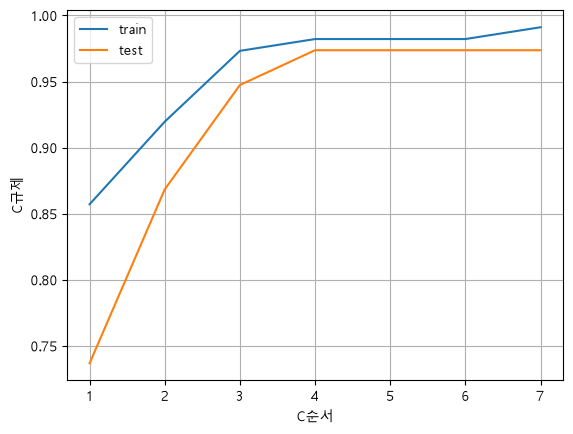

In [116]:
num = [1,2,3,4,5,6,7]
plt.plot(num,train_score)
plt.plot(num,test_score)
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [110]:
#품종 확인
print(lr.classes_)

['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [111]:
#품종별 점수와 확률 확인
lr.predict_proba(test_scaled[:5])   # 확률구하기(test 꽃 앞에서부터 다섯개를 가져오기)
decisions = lr.decision_function(test_scaled[:5])   #각 품종에 대한 점수 구하기
soft1 = softmax(decisions,axis=1)   # 각 꽃의 가로 방향 점수 3개끼리 계산
np.round(soft1,decimals=3)          # 넷째 자리에서 반올림

array([[0.   , 0.017, 0.983],
       [0.   , 0.   , 1.   ],
       [1.   , 0.   , 0.   ],
       [0.985, 0.015, 0.   ],
       [0.991, 0.009, 0.   ]])

In [112]:
# 정확도
print("train정확도: ",lr.score(train_scaled,train_label))
print("test정확도: ",lr.score(test_scaled,test_label))

train정확도:  0.9821428571428571
test정확도:  0.9736842105263158


In [113]:
print(*data[0], sep='\t')

5.1	3.5	1.4	0.2


In [114]:
# 5.1   3.5 1.4	0.2
#'Iris-setosa', 'Iris-versicolor', 'Iris-virginica'

# 예측할 꽃의 데이터 입력 및 숫자 변환
in_data ='5.1	3.5	1.4	0.2'
in_data = in_data.split("\t")
in_data = list(map(float,in_data))   #나눈 문자열 각각을 실수로 바꿔 리스트로 만들기

#정규화
in_sclaed =ss.transform([in_data])

#확률예측
result = lr.predict(in_sclaed)          #결과: 품종
result2 = lr.predict_proba(in_sclaed)   #결과: 세개의 품종 각각의 확률

if result[0] == 'Iris-setosa':
    result3 = result2[0][0]
elif result[0] == 'Iris-versicolor':
    result3 = result2[0][1]
elif result[0] == 'Iris-virginica':
    result3 = result2[0][2]
print('test:',result3)

print(f"붓꽃품종분류 : {result3*100:.2f}% 확률로 {result[0]} 판별됩니다.")


test: 0.9989446579104508
붓꽃품종분류 : 99.89% 확률로 Iris-setosa 판별됩니다.
